# Part B: Transport Network and Accessibility Modelling

This notebook develops the car and public-transport routing workflows used to calculate travel times between Burnie SA1 origins and essential-service destinations.

In [1]:
# Import the main libraries

from pathlib import Path

import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import osmnx as ox
import r5py

print("Transport modelling environment is working.")
print("r5py version:", r5py.__version__)

Transport modelling environment is working.
r5py version: 1.1.7


In [2]:
# Set project paths

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

data_raw = project_root / "data" / "raw"
analysis_ready = project_root / "data" / "processed" / "analysis_ready"

print("Raw data folder exists:", data_raw.exists())
print("Analysis-ready folder exists:", analysis_ready.exists())

Raw data folder exists: True
Analysis-ready folder exists: True


## B1. Transport Network Inputs

The routing network is built from the Tasmania OpenStreetMap PBF extract and the Metro Tasmania GTFS timetable. The input files are checked before constructing the R5 transport network.

In [3]:
# Set the OSM and GTFS input paths

osm_pbf = (
    data_raw
    / "Transport (inc. Subfolders)"
    / "Open Street Map TAS from Geofabrik"
    / "tasmania-260927.osm.pbf"
)

gtfs_folder = (
    data_raw
    / "Transport (inc. Subfolders)"
    / "METRO Data"
)

print("OSM PBF exists:", osm_pbf.exists())
print("GTFS folder exists:", gtfs_folder.exists())

OSM PBF exists: True
GTFS folder exists: True


In [4]:
# Check the Metro GTFS files

required_gtfs_files = [
    "agency.txt",
    "calendar.txt",
    "calendar_dates.txt",
    "routes.txt",
    "stop_times.txt",
    "stops.txt",
    "trips.txt"
]

for file_name in required_gtfs_files:
    file_path = gtfs_folder / file_name
    print(f"{file_name}: {file_path.exists()}")

agency.txt: True
calendar.txt: True
calendar_dates.txt: True
routes.txt: True
stop_times.txt: True
stops.txt: True
trips.txt: True


## B2. Build the R5 Transport Network

The Metro Tasmania GTFS files are packaged into a single GTFS archive and combined with the OpenStreetMap PBF extract to create the multimodal R5 transport network. This network will support both private-car and public-transport travel-time calculations.

In [6]:
# Create a GTFS ZIP file for r5py

import zipfile

gtfs_zip = analysis_ready / "metro_gtfs.zip"

with zipfile.ZipFile(
    gtfs_zip,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zip_file:

    for file_path in gtfs_folder.glob("*.txt"):
        zip_file.write(
            file_path,
            arcname=file_path.name
        )

print("GTFS ZIP created:", gtfs_zip.exists())
print("GTFS ZIP path:", gtfs_zip)

GTFS ZIP created: True
GTFS ZIP path: c:\Users\ggachara\Downloads\AT3_Group4_2026\AT3_Group4_2026\data\processed\analysis_ready\metro_gtfs.zip


### B3. Create a Burnie OpenStreetMap Extract

The statewide OSM PBF contains features with an unexpectedly large geographic extent, causing R5 to reject the street network. A buffered Burnie extract is therefore created so that the routing network contains the study area and nearby connecting roads without loading irrelevant statewide features.

In [8]:
# Load the ABS Burnie LGA boundary

g62_path = (
    data_raw
    / "CENSUS TAS Method of Travel. Src ABS"
    / "G62_TAS_GDA2020.gpkg"
)

lga = gpd.read_file(
    g62_path,
    layer="G62_LGA_2021_TAS"
)

burnie_lga = lga[
    lga["LGA_NAME_2021"].str.contains(
        "Burnie",
        case=False,
        na=False
    )
].copy()

# Add a 5 km buffer around Burnie
burnie_buffer = burnie_lga.to_crs("EPSG:7855")
burnie_buffer["geometry"] = burnie_buffer.geometry.buffer(5000)

# Convert back to longitude/latitude for Osmium
burnie_buffer_wgs84 = burnie_buffer.to_crs("EPSG:4326")

minx, miny, maxx, maxy = burnie_buffer_wgs84.total_bounds

print("Buffered Burnie bounding box:")
print("min longitude:", minx)
print("min latitude:", miny)
print("max longitude:", maxx)
print("max latitude:", maxy)

print(
    f"\nOsmium bbox: {minx},{miny},{maxx},{maxy}"
)

Buffered Burnie bounding box:
min longitude: 145.57788165450307
min latitude: -41.40132167647805
max longitude: 146.04466655004958
max latitude: -40.99166113410229

Osmium bbox: 145.57788165450307,-41.40132167647805,146.04466655004958,-40.99166113410229


In [9]:
# Use the buffered Burnie OSM extract for routing

burnie_pbf = (
    analysis_ready
    / "burnie_buffered.osm.pbf"
)

print("Burnie PBF exists:", burnie_pbf.exists())
print("Burnie PBF:", burnie_pbf)

Burnie PBF exists: True
Burnie PBF: c:\Users\ggachara\Downloads\AT3_Group4_2026\AT3_Group4_2026\data\processed\analysis_ready\burnie_buffered.osm.pbf


In [10]:
# Build the multimodal R5 transport network

transport_network = r5py.TransportNetwork(
    burnie_pbf,
    [gtfs_zip]
)

print("R5 transport network created successfully.")

R5 transport network created successfully.


## B4. GTFS Service Calendar

The Metro Tasmania GTFS calendar is inspected to identify a representative weekday on which scheduled public-transport services operate. This avoids calculating public-transport accessibility on a date with no service or an exceptional timetable.

In [11]:
# Load the GTFS service calendar

calendar = pd.read_csv(
    gtfs_folder / "calendar.txt"
)

calendar_dates = pd.read_csv(
    gtfs_folder / "calendar_dates.txt"
)

feed_info = pd.read_csv(
    gtfs_folder / "feed_info.txt"
)

print("GTFS calendar:")
display(calendar)

print("\nGTFS feed information:")
display(feed_info)

GTFS calendar:


,service_id,monday,tuesday,wednesday,thursday,friday,saturday,sunday,start_date,end_date
0,CA2026-CA_N_Sa-Saturday-005,0,0,0,0,0,1,0,20260829,20261128
1,CA2026-CA_N_SH-Weekday-005,1,1,1,1,1,0,0,20261005,20261016
2,CA2026-CA_N_SSH-Sunday-005,0,0,0,0,0,0,1,20261004,20261018
3,CA2026-CA_N_Su-Sunday-005,0,0,0,0,0,0,1,20260830,20261129
4,CA2026-CA_N_Wk-Weekday-005,1,1,1,1,1,0,0,20260825,20261130
...,...,...,...,...,...,...,...,...,...,...
72,TL2026-TL_W_SSH-Sunday-005,0,0,0,0,0,0,1,20261004,20261018
73,TL2026-TL_W_Su-Sunday-005,0,0,0,0,0,0,1,20260830,20261129
74,TL2026-TL_W_Wk-Weekday-005,1,1,1,1,1,0,0,20260825,20261130
75,TL2026-TL_W_Wk-Weekday-005-1111000,1,1,1,1,0,0,0,20260825,20261130



GTFS feed information:


,feed_publisher_name,feed_publisher_url,feed_lang,feed_start_date,feed_end_date,feed_version
0,Public Transport Tasmania,https://www.transport.tas.gov.au/public_transport,en,20260902,20261130,23


In [12]:
# Check the overall GTFS service period

calendar["start_date"] = pd.to_datetime(
    calendar["start_date"].astype(str),
    format="%Y%m%d"
)

calendar["end_date"] = pd.to_datetime(
    calendar["end_date"].astype(str),
    format="%Y%m%d"
)

print("Earliest service date:", calendar["start_date"].min())
print("Latest service date:", calendar["end_date"].max())

print("\nWeekday service flags:")
display(
    calendar[
        [
            "service_id",
            "monday",
            "tuesday",
            "wednesday",
            "thursday",
            "friday",
            "saturday",
            "sunday",
            "start_date",
            "end_date"
        ]
    ]
)

Earliest service date: 2026-08-25 00:00:00
Latest service date: 2026-11-30 00:00:00

Weekday service flags:


,service_id,monday,tuesday,wednesday,thursday,friday,saturday,sunday,start_date,end_date
0,CA2026-CA_N_Sa-Saturday-005,0,0,0,0,0,1,0,2026-08-29,2026-11-28
1,CA2026-CA_N_SH-Weekday-005,1,1,1,1,1,0,0,2026-10-05,2026-10-16
2,CA2026-CA_N_SSH-Sunday-005,0,0,0,0,0,0,1,2026-10-04,2026-10-18
3,CA2026-CA_N_Su-Sunday-005,0,0,0,0,0,0,1,2026-08-30,2026-11-29
4,CA2026-CA_N_Wk-Weekday-005,1,1,1,1,1,0,0,2026-08-25,2026-11-30
...,...,...,...,...,...,...,...,...,...,...
72,TL2026-TL_W_SSH-Sunday-005,0,0,0,0,0,0,1,2026-10-04,2026-10-18
73,TL2026-TL_W_Su-Sunday-005,0,0,0,0,0,0,1,2026-08-30,2026-11-29
74,TL2026-TL_W_Wk-Weekday-005,1,1,1,1,1,0,0,2026-08-25,2026-11-30
75,TL2026-TL_W_Wk-Weekday-005-1111000,1,1,1,1,0,0,0,2026-08-25,2026-11-30


In [13]:
# Check GTFS service exceptions for the proposed analysis date

analysis_date = 20261020

date_exceptions = calendar_dates[
    calendar_dates["date"] == analysis_date
].copy()

print("GTFS exceptions on 20 October 2026:",
      len(date_exceptions))

display(date_exceptions)

GTFS exceptions on 20 October 2026: 0


,service_id,date,exception_type


## B5. Prepare Routing Origins and Destinations

The 56 Burnie SA1 representative points are used as routing origins and the 26 essential-service locations are used as destinations. Both datasets are converted to WGS84 and assigned unique identifiers for use in R5.

In [14]:
# Load and prepare the routing origins

origins = gpd.read_file(
    analysis_ready / "burnie_sa1_origins.gpkg"
).to_crs("EPSG:4326")

origins_r5 = origins[
    ["SA1_CODE_2021", "geometry"]
].copy()

origins_r5 = origins_r5.rename(
    columns={"SA1_CODE_2021": "id"}
)

origins_r5["id"] = origins_r5["id"].astype(str)


# Load and prepare the routing destinations

destinations = gpd.read_file(
    analysis_ready / "burnie_essential_services.gpkg"
).to_crs("EPSG:4326")

destinations_r5 = destinations[
    ["name", "service_type", "geometry"]
].copy()

destinations_r5["id"] = [
    f"dest_{i:02d}"
    for i in range(1, len(destinations_r5) + 1)
]

print("Origins:", len(origins_r5))
print("Destinations:", len(destinations_r5))
print("Origins CRS:", origins_r5.crs)
print("Destinations CRS:", destinations_r5.crs)

Origins: 56
Destinations: 26
Origins CRS: EPSG:4326
Destinations CRS: EPSG:4326


In [15]:
# Select one rural origin and one health destination for a test route

test_origin = origins_r5[
    origins_r5["id"] == "60401107604"
].copy()

test_destination = destinations_r5[
    destinations_r5["name"] == "North West Regional Hospital"
].copy()

print("Test origins:", len(test_origin))
print("Test destinations:", len(test_destination))

display(test_destination[["id", "name", "service_type"]])

Test origins: 1
Test destinations: 1


,id,name,service_type
13,dest_14,North West Regional Hospital,Health


In [16]:
# Calculate one test car travel time

import datetime

departure_time = datetime.datetime(
    2026, 10, 20, 9, 0, 0
)

test_car_time = r5py.TravelTimeMatrix(
    transport_network,
    origins=test_origin,
    destinations=test_destination,
    transport_modes=[
        r5py.TransportMode.CAR
    ],
    departure=departure_time,
    snap_to_network=True
)

display(test_car_time)

,from_id,to_id,travel_time
0,60401107604,dest_14,39


## B7. Car Travel-Time Matrix

Car travel times are calculated from each Burnie SA1 origin to every essential-service destination using the R5 street network. The resulting origin-destination matrix provides the basis for measuring accessibility by private car.

In [17]:
# Calculate car travel times for all origins and destinations

car_matrix = r5py.TravelTimeMatrix(
    transport_network,
    origins=origins_r5,
    destinations=destinations_r5,
    transport_modes=[
        r5py.TransportMode.CAR
    ],
    departure=departure_time,
    snap_to_network=True
)

print("Expected OD pairs:", len(origins_r5) * len(destinations_r5))
print("Returned OD pairs:", len(car_matrix))

display(car_matrix.head())

Expected OD pairs: 1456
Returned OD pairs: 1456


,from_id,to_id,travel_time
0,60401107501,dest_01,10
1,60401107501,dest_02,7
2,60401107501,dest_03,5
3,60401107501,dest_04,6
4,60401107501,dest_05,9


In [18]:
# Check the car travel-time results

print("Missing travel times:",
      car_matrix["travel_time"].isna().sum())

print("\nCar travel-time summary (minutes):")
print(car_matrix["travel_time"].describe())

Missing travel times: 0

Car travel-time summary (minutes):
count    1456.000000
mean        8.210852
std         5.801900
min         0.000000
25%         5.000000
50%         7.000000
75%        10.000000
max        40.000000
Name: travel_time, dtype: float64


In [19]:
# Add destination information to the car matrix

destination_lookup = destinations_r5[
    ["id", "name", "service_type"]
].copy()

car_matrix = car_matrix.merge(
    destination_lookup,
    left_on="to_id",
    right_on="id",
    how="left"
)

car_matrix = car_matrix.drop(columns="id")

display(car_matrix.head(10))

,from_id,to_id,travel_time,name,service_type
0,60401107501,dest_01,10,Marist Regional College,School
1,60401107501,dest_02,7,Stella Maris Primary School,School
2,60401107501,dest_03,5,Montello Primary School,School
3,60401107501,dest_04,6,Leighland Christian School,School
4,60401107501,dest_05,9,Burnie High School,School
5,60401107501,dest_06,8,Cooee Primary School,School
6,60401107501,dest_07,7,Burnie Primary School,School
7,60401107501,dest_08,4,Parklands High School,School
8,60401107501,dest_09,2,Romaine Park Primary School,School
9,60401107501,dest_10,7,Havenview Primary School,School


In [20]:
# Save the completed car travel-time matrix

car_output = (
    analysis_ready
    / "car_travel_times_20261020_0900.csv"
)

car_matrix.to_csv(
    car_output,
    index=False
)

print("Car matrix saved:", car_output.exists())

Car matrix saved: True


## B8. Test Public-Transport Routing

Public-transport travel times are calculated using the Metro Tasmania GTFS timetable and walking access to and from transit stops. A 60-minute departure window from 09:00 to 10:00 is used to account for variation in waiting time between scheduled services.

In [21]:
# Select an urban origin for the first public-transport test

pt_test_origin = origins_r5[
    origins_r5["id"] == "60401107501"
].copy()

print("Test origins:", len(pt_test_origin))
print("Test destination:", test_destination["name"].iloc[0])

Test origins: 1
Test destination: North West Regional Hospital


In [22]:
# Calculate one test public-transport travel time

test_pt_time = r5py.TravelTimeMatrix(
    transport_network,
    origins=pt_test_origin,
    destinations=test_destination,
    transport_modes=[
        r5py.TransportMode.TRANSIT
    ],
    access_modes=[
        r5py.TransportMode.WALK
    ],
    egress_modes=[
        r5py.TransportMode.WALK
    ],
    departure=departure_time,
    departure_time_window=datetime.timedelta(minutes=60),
    max_time=datetime.timedelta(minutes=120),
    max_time_walking=datetime.timedelta(minutes=30),
    snap_to_network=True
)

display(test_pt_time)

,from_id,to_id,travel_time
0,60401107501,dest_14,46


In [23]:
# Compare car and PT for the same test journey

test_car_comparison = car_matrix[
    (car_matrix["from_id"] == "60401107501")
    & (car_matrix["name"] == "North West Regional Hospital")
]

display(test_car_comparison)
print("\nPublic transport travel time:", test_pt_time["travel_time"].iloc[0], "minutes")

,from_id,to_id,travel_time,name,service_type
13,60401107501,dest_14,7,North West Regional Hospital,Health



Public transport travel time: 46 minutes


## B9. Public-Transport Travel-Time Matrix

Public-transport travel times are calculated from each Burnie SA1 origin to every essential-service destination using the Metro Tasmania GTFS timetable and walking access to and from public-transport stops. A 60-minute departure window from 09:00 to 10:00 is used to account for scheduled service frequency and waiting time.

In [24]:
# Calculate public-transport travel times for all origins and destinations

pt_matrix = r5py.TravelTimeMatrix(
    transport_network,
    origins=origins_r5,
    destinations=destinations_r5,
    transport_modes=[
        r5py.TransportMode.TRANSIT
    ],
    access_modes=[
        r5py.TransportMode.WALK
    ],
    egress_modes=[
        r5py.TransportMode.WALK
    ],
    departure=departure_time,
    departure_time_window=datetime.timedelta(minutes=60),
    max_time=datetime.timedelta(minutes=120),
    max_time_walking=datetime.timedelta(minutes=30),
    snap_to_network=True
)

print("Expected OD pairs:",
      len(origins_r5) * len(destinations_r5))

print("Returned OD pairs:",
      len(pt_matrix))

display(pt_matrix.head())

Expected OD pairs: 1456
Returned OD pairs: 1456


,from_id,to_id,travel_time
0,60401107501,dest_01,48.0
1,60401107501,dest_02,42.0
2,60401107501,dest_03,36.0
3,60401107501,dest_04,NaN
4,60401107501,dest_05,54.0


In [25]:
# Check the public-transport travel-time results

print("Missing travel times:",
      pt_matrix["travel_time"].isna().sum())

print("\nPublic-transport travel-time summary (minutes):")
print(pt_matrix["travel_time"].describe())

Missing travel times: 250

Public-transport travel-time summary (minutes):
count    1206.000000
mean       42.097015
std        19.419536
min         1.000000
25%        29.000000
50%        41.500000
75%        51.000000
max       119.000000
Name: travel_time, dtype: float64


In [26]:
# Add destination information to the public-transport matrix

pt_matrix = pt_matrix.merge(
    destination_lookup,
    left_on="to_id",
    right_on="id",
    how="left"
)

pt_matrix = pt_matrix.drop(columns="id")

display(pt_matrix.head(10))

,from_id,to_id,travel_time,name,service_type
0,60401107501,dest_01,48.0,Marist Regional College,School
1,60401107501,dest_02,42.0,Stella Maris Primary School,School
2,60401107501,dest_03,36.0,Montello Primary School,School
3,60401107501,dest_04,NaN,Leighland Christian School,School
4,60401107501,dest_05,54.0,Burnie High School,School
5,60401107501,dest_06,53.0,Cooee Primary School,School
6,60401107501,dest_07,48.0,Burnie Primary School,School
7,60401107501,dest_08,26.0,Parklands High School,School
8,60401107501,dest_09,11.0,Romaine Park Primary School,School
9,60401107501,dest_10,50.0,Havenview Primary School,School


In [27]:
# Save the completed public-transport travel-time matrix

pt_output = (
    analysis_ready
    / "pt_travel_times_20261020_0900.csv"
)

pt_matrix.to_csv(
    pt_output,
    index=False
)

print("PT matrix saved:", pt_output.exists())

PT matrix saved: True


In [28]:
# Summarise unreachable PT trips by service category

pt_unreachable = pt_matrix[
    pt_matrix["travel_time"].isna()
].copy()

print("Total unreachable PT trips:", len(pt_unreachable))

print("\nUnreachable trips by service type:")
print(
    pt_unreachable["service_type"]
    .value_counts()
)

Total unreachable PT trips: 250

Unreachable trips by service type:
service_type
School         111
Health          62
Pharmacy        43
Supermarket     34
Name: count, dtype: int64


In [29]:
# Find SA1 origins with the most unreachable destinations

unreachable_by_origin = (
    pt_unreachable
    .groupby("from_id")
    .size()
    .sort_values(ascending=False)
)

display(unreachable_by_origin.head(15))

from_id
60401107601    26
60401107709    26
60401107608    26
60401107607    26
60401107606    26
60401107604    26
60401108010    26
60401107805    26
60401107612    21
60401107507     1
60401107501     1
60401107506     1
60401107505     1
60401107503     1
60401107712     1
dtype: int64

## B10. Public-Transport Accessibility Diagnostics

Unreachable public-transport journeys are summarised by service category and SA1 origin. Because the number of destinations differs between service categories, percentages are used alongside raw counts to allow meaningful comparison.

In [30]:
# Calculate the percentage of unreachable PT trips by service category

pt_category_summary = (
    pt_matrix
    .groupby("service_type")
    .agg(
        total_trips=("travel_time", "size"),
        reachable_trips=("travel_time", "count")
    )
)

pt_category_summary["unreachable_trips"] = (
    pt_category_summary["total_trips"]
    - pt_category_summary["reachable_trips"]
)

pt_category_summary["unreachable_pct"] = (
    pt_category_summary["unreachable_trips"]
    / pt_category_summary["total_trips"]
    * 100
)

display(pt_category_summary)

,total_trips,reachable_trips,unreachable_trips,unreachable_pct
service_type,,,,
Health,392,330,62,15.816327
Pharmacy,280,237,43,15.357143
School,560,449,111,19.821429
Supermarket,224,190,34,15.178571


In [31]:
# Count unreachable PT destinations for every SA1 origin

unreachable_counts = (
    pt_matrix
    .assign(
        unreachable=pt_matrix["travel_time"].isna().astype(int)
    )
    .groupby("from_id")["unreachable"]
    .sum()
    .reset_index()
)

unreachable_counts = unreachable_counts.rename(
    columns={
        "from_id": "SA1_CODE_2021",
        "unreachable": "pt_unreachable_count"
    }
)

display(
    unreachable_counts
    .sort_values("pt_unreachable_count", ascending=False)
    .head(15)
)

,SA1_CODE_2021,pt_unreachable_count
11,60401107607,26
10,60401107606,26
22,60401107709,26
12,60401107608,26
9,60401107604,26
8,60401107601,26
54,60401108010,26
31,60401107805,26
13,60401107612,21
5,60401107506,1


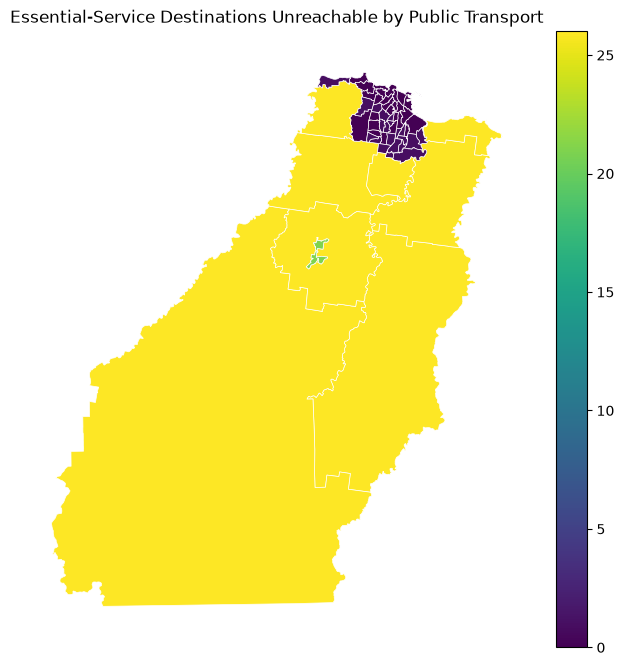

In [32]:
# Map the number of unreachable PT destinations by SA1

sa1_access = gpd.read_file(
    analysis_ready / "burnie_sa1_seifa.gpkg"
)

sa1_access["SA1_CODE_2021"] = (
    sa1_access["SA1_CODE_2021"].astype(str)
)

sa1_access = sa1_access.merge(
    unreachable_counts,
    on="SA1_CODE_2021",
    how="left"
)

sa1_access["pt_unreachable_count"] = (
    sa1_access["pt_unreachable_count"].fillna(0)
)

fig, ax = plt.subplots(figsize=(8, 8))

sa1_access.plot(
    column="pt_unreachable_count",
    ax=ax,
    legend=True,
    edgecolor="white",
    linewidth=0.5
)

ax.set_title(
    "Essential-Service Destinations Unreachable by Public Transport"
)
ax.set_axis_off()

plt.show()

## B11. Expanded Six-Category Accessibility Routing

The routing analysis is repeated using the expanded destination dataset containing four essential-service categories and two local-opportunity categories: greenspace and leisure. The original four-category travel-time matrices are retained separately.

In [33]:
# Check the routing objects currently available in this notebook

objects_to_check = [
    "r5py",
    "transport_network",
    "origins_r5",
    "departure_time",
    "analysis_ready"
]

for item in objects_to_check:
    print(f"{item}: {item in globals()}")

r5py: True
transport_network: True
origins_r5: True
departure_time: True
analysis_ready: True


In [34]:
# Load the expanded six-category destination dataset

expanded_destinations = gpd.read_file(
    analysis_ready / "burnie_accessibility_destinations.gpkg"
).to_crs("EPSG:4326")

expanded_destinations_r5 = expanded_destinations[
    ["name", "service_type", "subtype", "geometry"]
].copy()

expanded_destinations_r5["id"] = [
    f"dest_{i:03d}"
    for i in range(1, len(expanded_destinations_r5) + 1)
]

print("Expanded destinations:", len(expanded_destinations_r5))

print("\nDestinations by category:")
print(
    expanded_destinations_r5["service_type"]
    .value_counts()
)

Expanded destinations: 108

Destinations by category:
service_type
Leisure        52
Greenspace     30
School         10
Health          7
Pharmacy        5
Supermarket     4
Name: count, dtype: int64


### B12. Expanded Car Travel-Time Matrix

Car travel times are recalculated for the expanded six-category destination dataset. The original four-category matrix is retained separately for comparison and reproducibility.

In [35]:
# Calculate car travel times to all expanded destinations

expanded_car_matrix = r5py.TravelTimeMatrix(
    transport_network,
    origins=origins_r5,
    destinations=expanded_destinations_r5,
    transport_modes=[
        r5py.TransportMode.CAR
    ],
    departure=departure_time,
    snap_to_network=True
)

print(
    "Expected OD pairs:",
    len(origins_r5) * len(expanded_destinations_r5)
)

print(
    "Returned OD pairs:",
    len(expanded_car_matrix)
)

print(
    "Missing travel times:",
    expanded_car_matrix["travel_time"].isna().sum()
)

print("\nExpanded car travel-time summary (minutes):")
print(
    expanded_car_matrix["travel_time"].describe()
)

Expected OD pairs: 6048
Returned OD pairs: 6048
Missing travel times: 0

Expanded car travel-time summary (minutes):
count    6048.000000
mean        9.366733
std         6.184964
min         0.000000
25%         6.000000
50%         8.000000
75%        11.000000
max        48.000000
Name: travel_time, dtype: float64


In [36]:
# Add destination information to the expanded car matrix

expanded_destination_lookup = expanded_destinations_r5[
    ["id", "name", "service_type", "subtype"]
].copy()

expanded_car_matrix = expanded_car_matrix.merge(
    expanded_destination_lookup,
    left_on="to_id",
    right_on="id",
    how="left"
)

expanded_car_matrix = expanded_car_matrix.drop(
    columns="id"
)

display(expanded_car_matrix.head(10))

,from_id,to_id,travel_time,name,service_type,subtype
0,60401107501,dest_001,10,Marist Regional College,School,School
1,60401107501,dest_002,7,Stella Maris Primary School,School,School
2,60401107501,dest_003,5,Montello Primary School,School,School
3,60401107501,dest_004,6,Leighland Christian School,School,School
4,60401107501,dest_005,9,Burnie High School,School,School
5,60401107501,dest_006,8,Cooee Primary School,School,School
6,60401107501,dest_007,7,Burnie Primary School,School,School
7,60401107501,dest_008,4,Parklands High School,School,School
8,60401107501,dest_009,2,Romaine Park Primary School,School,School
9,60401107501,dest_010,7,Havenview Primary School,School,School


In [38]:
# Save the expanded six-category car matrix

expanded_car_output = (
    analysis_ready
    / "car_travel_times_6categories_20261020_0900.csv"
)

expanded_car_matrix.to_csv(
    expanded_car_output,
    index=False
)

print(
    "Expanded car matrix saved:",
    expanded_car_output.exists()
)

Expanded car matrix saved: True


### B13. Expanded Public-Transport Travel-Time Matrix

Public-transport travel times are recalculated for the expanded six-category destination dataset using the same weekday departure period, walking allowance and maximum journey time as the original analysis.

In [39]:
# Calculate PT travel times to all expanded destinations

expanded_pt_matrix = r5py.TravelTimeMatrix(
    transport_network,
    origins=origins_r5,
    destinations=expanded_destinations_r5,
    transport_modes=[
        r5py.TransportMode.TRANSIT
    ],
    access_modes=[
        r5py.TransportMode.WALK
    ],
    egress_modes=[
        r5py.TransportMode.WALK
    ],
    departure=departure_time,
    departure_time_window=datetime.timedelta(minutes=60),
    max_time=datetime.timedelta(minutes=120),
    max_time_walking=datetime.timedelta(minutes=30),
    snap_to_network=True
)

print(
    "Expected OD pairs:",
    len(origins_r5) * len(expanded_destinations_r5)
)

print(
    "Returned OD pairs:",
    len(expanded_pt_matrix)
)

print(
    "Missing travel times:",
    expanded_pt_matrix["travel_time"].isna().sum()
)

print("\nExpanded PT travel-time summary (minutes):")
print(
    expanded_pt_matrix["travel_time"].describe()
)

Expected OD pairs: 6048
Returned OD pairs: 6048
Missing travel times: 1288

Expanded PT travel-time summary (minutes):
count    4760.000000
mean       47.146008
std        20.849421
min         0.000000
25%        34.000000
50%        46.000000
75%        58.000000
max       119.000000
Name: travel_time, dtype: float64


In [40]:
# Add destination information to the expanded PT matrix

expanded_pt_matrix = expanded_pt_matrix.merge(
    expanded_destination_lookup,
    left_on="to_id",
    right_on="id",
    how="left"
)

expanded_pt_matrix = expanded_pt_matrix.drop(
    columns="id"
)

display(expanded_pt_matrix.head(10))

,from_id,to_id,travel_time,name,service_type,subtype
0,60401107501,dest_001,48.0,Marist Regional College,School,School
1,60401107501,dest_002,42.0,Stella Maris Primary School,School,School
2,60401107501,dest_003,36.0,Montello Primary School,School,School
3,60401107501,dest_004,NaN,Leighland Christian School,School,School
4,60401107501,dest_005,54.0,Burnie High School,School,School
5,60401107501,dest_006,53.0,Cooee Primary School,School,School
6,60401107501,dest_007,48.0,Burnie Primary School,School,School
7,60401107501,dest_008,26.0,Parklands High School,School,School
8,60401107501,dest_009,11.0,Romaine Park Primary School,School,School
9,60401107501,dest_010,50.0,Havenview Primary School,School,School


In [41]:
# Save the expanded six-category PT matrix

expanded_pt_output = (
    analysis_ready
    / "pt_travel_times_6categories_20261020_0900.csv"
)

expanded_pt_matrix.to_csv(
    expanded_pt_output,
    index=False
)

print(
    "Expanded PT matrix saved:",
    expanded_pt_output.exists()
)

Expanded PT matrix saved: True


### B14. Expanded Public-Transport Accessibility Diagnostics

Unreachable public-transport journeys are summarised by destination category. Percentages are calculated because the six categories contain different numbers of destinations.

In [42]:
# Summarise unreachable PT journeys by category

pt_category_qa = (
    expanded_pt_matrix
    .groupby("service_type")
    .agg(
        total_trips=("travel_time", "size"),
        reachable_trips=("travel_time", "count")
    )
)

pt_category_qa["unreachable_trips"] = (
    pt_category_qa["total_trips"]
    - pt_category_qa["reachable_trips"]
)

pt_category_qa["unreachable_pct"] = (
    pt_category_qa["unreachable_trips"]
    / pt_category_qa["total_trips"]
    * 100
)

display(
    pt_category_qa.sort_values(
        "unreachable_pct",
        ascending=False
    )
)

,total_trips,reachable_trips,unreachable_trips,unreachable_pct
service_type,,,,
Leisure,2912,2144,768,26.373626
School,560,449,111,19.821429
Greenspace,1680,1410,270,16.071429
Health,392,330,62,15.816327
Pharmacy,280,237,43,15.357143
Supermarket,224,190,34,15.178571


In [43]:
# Check unreachable PT journeys by leisure subtype

leisure_pt_qa = (
    expanded_pt_matrix[
        expanded_pt_matrix["service_type"] == "Leisure"
    ]
    .groupby("subtype")
    .agg(
        total_trips=("travel_time", "size"),
        reachable_trips=("travel_time", "count")
    )
)

leisure_pt_qa["unreachable_trips"] = (
    leisure_pt_qa["total_trips"]
    - leisure_pt_qa["reachable_trips"]
)

leisure_pt_qa["unreachable_pct"] = (
    leisure_pt_qa["unreachable_trips"]
    / leisure_pt_qa["total_trips"]
    * 100
)

display(
    leisure_pt_qa.sort_values(
        "unreachable_pct",
        ascending=False
    )
)

,total_trips,reachable_trips,unreachable_trips,unreachable_pct
subtype,,,,
recreation_ground,784,358,426,54.336735
playground,1456,1222,234,16.071429
sports_centre,616,517,99,16.071429
swimming_pool,56,47,9,16.071429
